Harshavarthan SB 24BAD033
TensorFlow: 2.21.0
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images : 60000 | each (28, 28) | dtype uint8
Testing images  : 10000 | each (28, 28)
Pixel range     : 0 - 255
      class  train  test
T-shirt/top   6000  1000
    Trouser   6000  1000
   Pullover   6000  1000
      Dress   6000  1000
       Coat   6000  1000
     Sandal   6000  1000
      Shirt   6000  1000
    Sneaker   6000  1000
        Bag   6000  1000
 Ankle boot   6000  1000


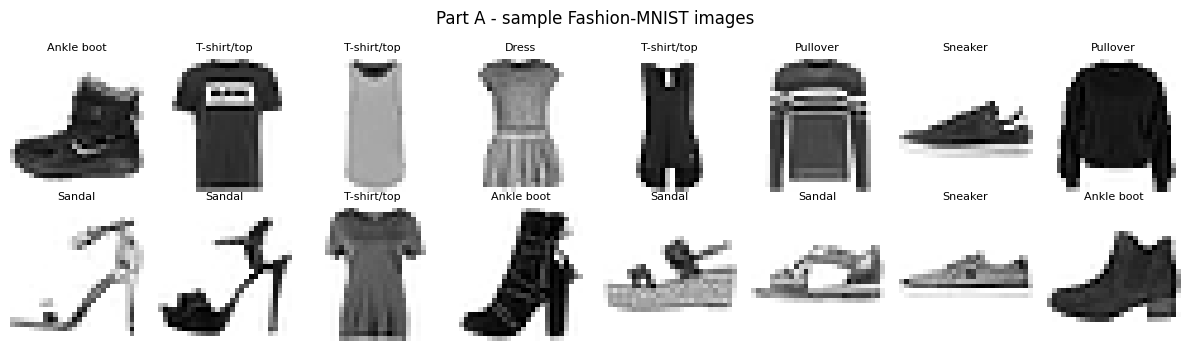


After scaling -> min: 0.0 max: 1.0
Flattened shapes: (60000, 784) (10000, 784)
Target arrays are identical to the input arrays: True


In [1]:
print("Harshavarthan SB 24BAD033")
# Part A
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(33)
print("TensorFlow:", tf.__version__)

# Load the Fashion-MNIST dataset (a drop-in alternative to MNIST suggested in the lab sheet)
(train_imgs, train_lbls), (test_imgs, test_lbls) = keras.datasets.fashion_mnist.load_data()
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# Explore: number of images and their dimensions
print("Training images :", train_imgs.shape[0], "| each", train_imgs.shape[1:], "| dtype", train_imgs.dtype)
print("Testing images  :", test_imgs.shape[0], "| each", test_imgs.shape[1:])
print("Pixel range     :", train_imgs.min(), "-", train_imgs.max())
print(pd.DataFrame({"class": class_names, "train": np.bincount(train_lbls), "test": np.bincount(test_lbls)}).to_string(index=False))

# Display sample images
fig, axs = plt.subplots(2, 8, figsize=(12, 3.6))
for ax, img, lbl in zip(axs.flat, train_imgs[:16], train_lbls[:16]):
    ax.imshow(img, cmap="gray_r")
    ax.set_title(class_names[lbl], fontsize=8)
    ax.axis("off")
fig.suptitle("Part A - sample Fashion-MNIST images")
plt.tight_layout()
plt.show()

# Convert to float32 in [0, 1] and flatten each 28 x 28 image into a 784-dimensional vector
x_train = (train_imgs / 255.0).astype("float32").reshape(len(train_imgs), -1)
x_test = (test_imgs / 255.0).astype("float32").reshape(len(test_imgs), -1)
print("\nAfter scaling -> min:", x_train.min(), "max:", x_train.max())
print("Flattened shapes:", x_train.shape, x_test.shape)

# An autoencoder learns to reproduce its input, so the targets are the inputs themselves
y_train_ae, y_test_ae = x_train, x_test
print("Target arrays are identical to the input arrays:", y_train_ae is x_train and y_test_ae is x_test)


In [2]:
print("Harshavarthan SB 24BAD033")
# Part B
INPUT_DIM = 784
LATENT_DIM = 32

# Encoder: 784 -> 256 -> 128 -> 32 (ReLU hidden layers)
encoder = keras.Sequential([
    keras.Input(shape=(INPUT_DIM,)),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(LATENT_DIM, activation="relu", name="latent"),
], name="encoder")

# Decoder: 32 -> 128 -> 256 -> 784 (Sigmoid output keeps pixels in [0, 1])
decoder = keras.Sequential([
    keras.Input(shape=(LATENT_DIM,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(256, activation="relu"),
    layers.Dense(INPUT_DIM, activation="sigmoid", name="reconstruction"),
], name="decoder")

# Combine the encoder and decoder into a single autoencoder model
autoencoder = keras.Sequential([encoder, decoder], name="autoencoder")

# Model summaries
encoder.summary()
decoder.summary()
autoencoder.summary()
print(f"\nCompression: {INPUT_DIM} inputs -> {LATENT_DIM} latent values ({INPUT_DIM / LATENT_DIM:.1f}x smaller)")


Harshavarthan SB 24BAD033


Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 32)             │         4,128 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 237,984 (929.62 KB)

 Trainable params: 237,984 (929.62 KB)

 Non-trainable params: 0 (0.00 B)

... (7 outputs left out)

 Total params: 476,720 (1.82 MB)

 Trainable params: 476,720 (1.82 MB)

 Non-trainable params: 0 (0.00 B)


Compression: 784 inputs -> 32 latent values (24.5x smaller)


Harshavarthan SB 24BAD033
Epoch 1/15
235/235 - 15s - 63ms/step - loss: 0.0427 - val_loss: 0.0235
Epoch 2/15
235/235 - 15s - 63ms/step - loss: 0.0208 - val_loss: 0.0189
Epoch 3/15
235/235 - 6s - 27ms/step - loss: 0.0178 - val_loss: 0.0169
Epoch 4/15
235/235 - 6s - 25ms/step - loss: 0.0162 - val_loss: 0.0157
Epoch 5/15
235/235 - 5s - 22ms/step - loss: 0.0150 - val_loss: 0.0147
Epoch 6/15
235/235 - 7s - 29ms/step - loss: 0.0143 - val_loss: 0.0140
Epoch 7/15
235/235 - 10s - 42ms/step - loss: 0.0136 - val_loss: 0.0135
Epoch 8/15
235/235 - 5s - 22ms/step - loss: 0.0131 - val_loss: 0.0131
Epoch 9/15
235/235 - 5s - 22ms/step - loss: 0.0126 - val_loss: 0.0127
Epoch 10/15
235/235 - 7s - 32ms/step - loss: 0.0123 - val_loss: 0.0124
Epoch 11/15
235/235 - 9s - 39ms/step - loss: 0.0120 - val_loss: 0.0120
Epoch 12/15
235/235 - 5s - 23ms/step - loss: 0.0117 - val_loss: 0.0118
Epoch 13/15
235/235 - 5s - 23ms/step - loss: 0.0114 - val_loss: 0.0116
Epoch 14/15
235/235 - 7s - 28ms/step - loss: 0.0112 - val

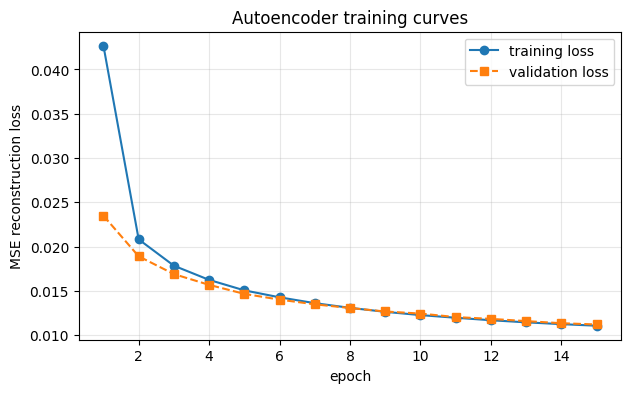

Final training loss  : 0.01105
Final validation loss: 0.01119


In [3]:
print("Harshavarthan SB 24BAD033")
# Part C
# Compile with the Adam optimizer and mean squared error as the reconstruction loss
autoencoder.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                    loss="mean_squared_error")

# Train: inputs are also the targets. The test set is used for validation after every epoch.
history = autoencoder.fit(x_train, y_train_ae,
                          batch_size=256,
                          epochs=15,
                          shuffle=True,
                          validation_data=(x_test, y_test_ae),
                          verbose=2)

# Training and validation loss for each epoch
loss_table = pd.DataFrame({"epoch": np.arange(1, 16),
                           "train_loss": history.history["loss"],
                           "val_loss": history.history["val_loss"]})
print(loss_table.round(5).to_string(index=False))

# Loss curves
plt.figure(figsize=(7, 4))
plt.plot(loss_table["epoch"], loss_table["train_loss"], "o-", label="training loss")
plt.plot(loss_table["epoch"], loss_table["val_loss"], "s--", label="validation loss")
plt.xlabel("epoch"); plt.ylabel("MSE reconstruction loss")
plt.title("Autoencoder training curves")
plt.grid(alpha=0.3); plt.legend()
plt.show()

print("Final training loss  :", round(loss_table["train_loss"].iloc[-1], 5))
print("Final validation loss:", round(loss_table["val_loss"].iloc[-1], 5))


Harshavarthan SB 24BAD033
Original input dimension: 784
Latent dimension        : 32
Latent matrix shape     : (10000, 32)


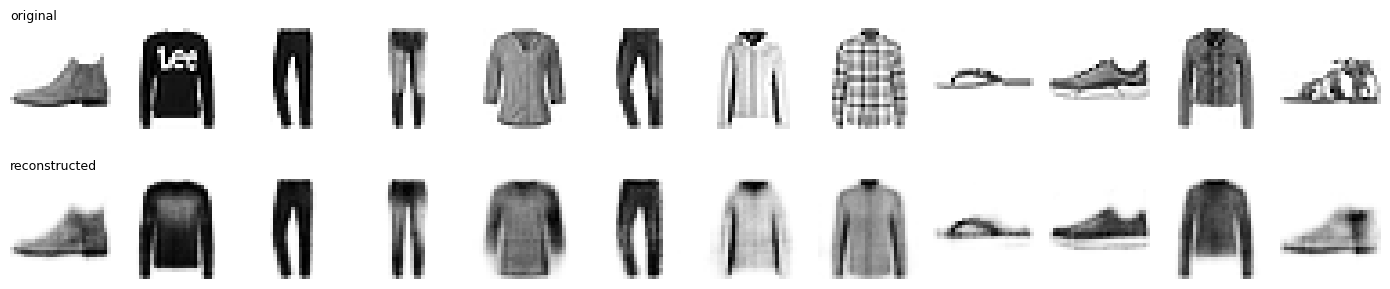

Mean reconstruction MSE: 0.01119

Average error per class (lowest = easiest to reconstruct):
Trouser        0.00562
Sneaker        0.00832
Coat           0.00975
Dress          0.01002
Pullover       0.01026
T-shirt/top    0.01028
Shirt          0.01126
Ankle boot     0.01141
Sandal         0.01680
Bag            0.01822

Best-reconstructed class : Trouser
Hardest class to rebuild : Bag
Observation: overall shape and brightness are kept; fine texture, thin patterns and sharp edges are lost.


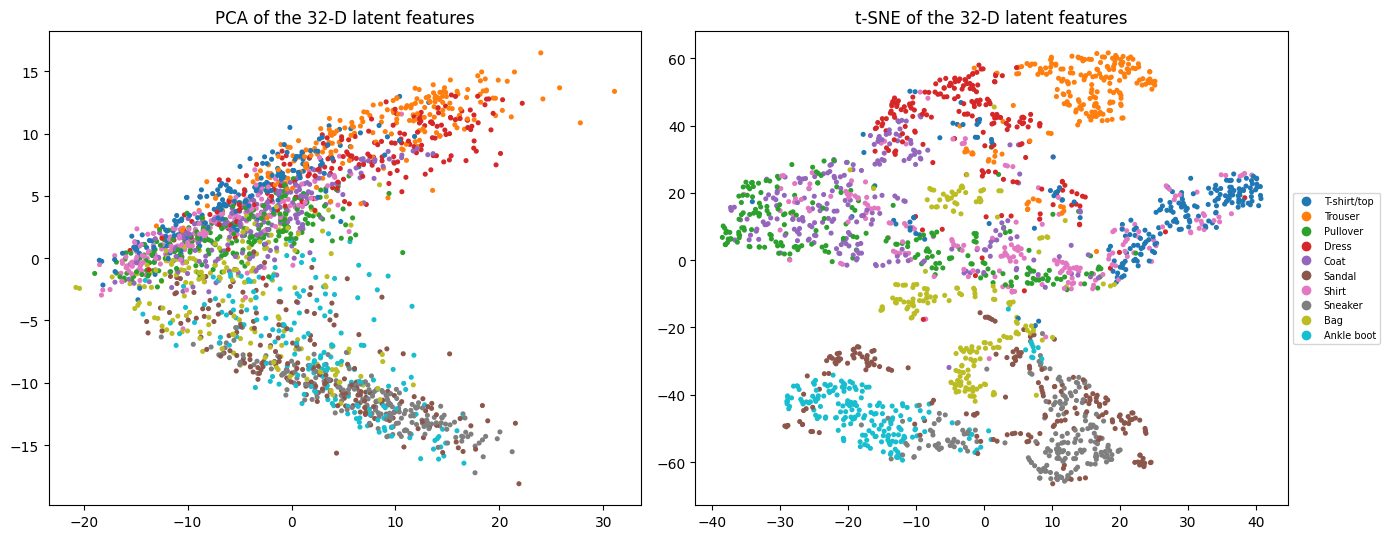

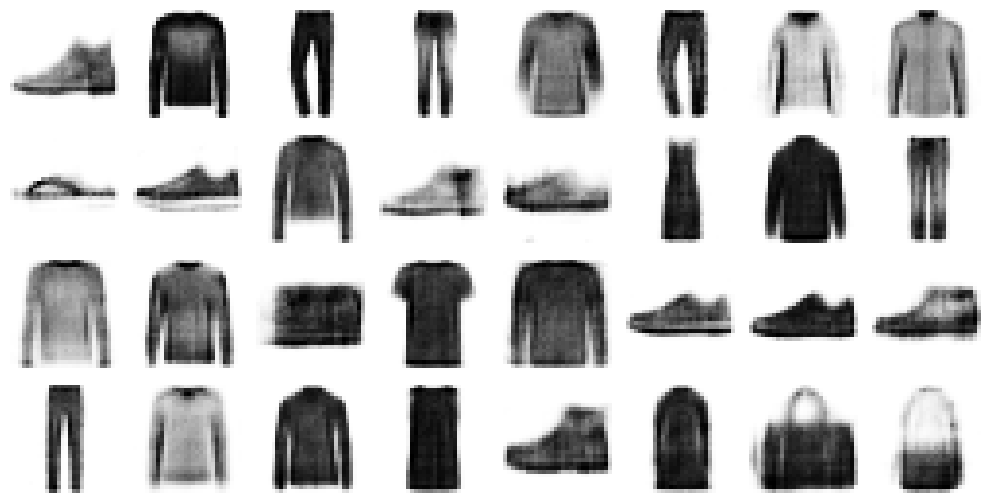

Saved: ['fashion_autoencoder.keras', 'fashion_encoder.keras', 'latent_test.npy', 'reconstructed_grid.png']


In [4]:
print("Harshavarthan SB 24BAD033")
# Part D
import os
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Use the trained encoder to turn test images into low-dimensional latent vectors
latent_test = encoder.predict(x_test, batch_size=512, verbose=0)
print("Original input dimension:", x_test.shape[1])
print("Latent dimension        :", latent_test.shape[1])
print("Latent matrix shape     :", latent_test.shape)

# Pass the latent vectors through the decoder to reconstruct the images
recon_test = decoder.predict(latent_test, batch_size=512, verbose=0)

# Original images (top row) and their reconstructions (bottom row)
idx = np.arange(12)
fig, axs = plt.subplots(2, len(idx), figsize=(14, 3.4))
for col, i in enumerate(idx):
    axs[0, col].imshow(x_test[i].reshape(28, 28), cmap="gray_r"); axs[0, col].axis("off")
    axs[1, col].imshow(recon_test[i].reshape(28, 28), cmap="gray_r"); axs[1, col].axis("off")
axs[0, 0].set_title("original", loc="left", fontsize=9)
axs[1, 0].set_title("reconstructed", loc="left", fontsize=9)
plt.tight_layout()
plt.show()

# Quantify what is kept and what is lost
per_image_mse = np.mean((x_test - recon_test) ** 2, axis=1)
print("Mean reconstruction MSE:", round(float(per_image_mse.mean()), 5))
error_by_class = pd.Series(per_image_mse).groupby([class_names[k] for k in test_lbls]).mean().sort_values()
print("\nAverage error per class (lowest = easiest to reconstruct):")
print(error_by_class.round(5).to_string())
print(f"\nBest-reconstructed class : {error_by_class.index[0]}")
print(f"Hardest class to rebuild : {error_by_class.index[-1]}")
print("Observation: overall shape and brightness are kept; fine texture, thin patterns and sharp edges are lost.")

# Visualise the 32-D latent features in two dimensions with PCA and t-SNE (first 2000 test images)
n_vis = 2000
pca_2d = PCA(n_components=2, random_state=0).fit_transform(latent_test[:n_vis])
tsne_2d = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(latent_test[:n_vis])

fig, axs = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, pts, name in zip(axs, (pca_2d, tsne_2d), ("PCA", "t-SNE")):
    sc = ax.scatter(pts[:, 0], pts[:, 1], c=test_lbls[:n_vis], cmap="tab10", s=7)
    ax.set_title(f"{name} of the 32-D latent features")
handles, _ = sc.legend_elements()
axs[1].legend(handles, class_names, fontsize=7, loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.tight_layout()
plt.show()

# Save the trained models, latent features and a grid of reconstructed images
os.makedirs("autoencoder_outputs", exist_ok=True)
autoencoder.save("autoencoder_outputs/fashion_autoencoder.keras")
encoder.save("autoencoder_outputs/fashion_encoder.keras")
np.save("autoencoder_outputs/latent_test.npy", latent_test)
fig, axs = plt.subplots(4, 8, figsize=(10, 5.2))
for ax, img in zip(axs.flat, recon_test[:32]):
    ax.imshow(img.reshape(28, 28), cmap="gray_r"); ax.axis("off")
plt.tight_layout()
plt.savefig("autoencoder_outputs/reconstructed_grid.png", dpi=120)
plt.show()
print("Saved:", sorted(os.listdir("autoencoder_outputs")))
